# Stage 3: Images

Each of the 77 unique images is rendered as it appears on the page, paired with the text around it, and described
by Claude Sonnet 5.5 so its content can be searched and cited like text. Code: `src/handbook_qa/images.py`
(rendering, context) and `src/handbook_qa/describe.py` (prompt, API call, cache).

Re-running:
- `REBUILD = True` renders the images again from the PDF (a few seconds).
- `RUN_API = True` describes images with the Claude API. It needs a key (`AZURE_KEY_VAULT_URL` or
  `ANTHROPIC_API_KEY`) and only describes images without a current cached description, unless `FORCE` is set.
- The current descriptions come from Claude Code Sonnet subagents given the same prompt (decision 09); they are
  cached in `artifacts/image_descriptions.jsonl` and reused here.

In [1]:
import asyncio
import collections
import io

import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

from handbook_qa.config import ROOT, load_settings
from handbook_qa.describe import PROMPT_VERSION, build_prompt, describe_all, is_current, load_cache
from handbook_qa.images import collect_images, load_image_index, render_images, save_image_index
from handbook_qa.pdf_extract import load_articles

REBUILD = False
RUN_API = False
FORCE = False
settings = load_settings()
paths = settings.paths
pd.set_option("display.max_colwidth", 120)


def preview(image_id: str, max_edge: int = 700) -> Image:
    """A small JPEG of a rendered image, so the saved notebook stays light."""
    im = PILImage.open(ROOT / "data/build/images" / f"{image_id}.png").convert("RGB")
    im.thumbnail((max_edge, max_edge))
    buffer = io.BytesIO()
    im.save(buffer, "JPEG", quality=80)
    return Image(data=buffer.getvalue(), format="jpeg")

## Render and collect context

In [2]:
articles = load_articles(paths.articles)
records = collect_images(articles)
rendered = all((ROOT / "data" / "build" / "images" / f"{r.image_id}.png").exists() for r in records)
if REBUILD or not rendered or not paths.image_index.exists():
    render_images(paths.pdf, records, paths.images, ROOT)
    save_image_index(records, paths.image_index)
    print("rendered", len(records), "images")
else:
    saved = {r.image_id: r for r in load_image_index(paths.image_index)}
    for r in records:  # take file, size and hash from the saved index
        s = saved[r.image_id]
        r.file, r.width, r.height, r.source_sha256 = s.file, s.width, s.height, s.source_sha256
    print("reused", len(records), "rendered images")

print(len(records), "unique images,", sum(len(r.occurrences) for r in records), "placements")
pd.DataFrame([{"image_id": r.image_id, "page": r.page, "size": f"{r.width}x{r.height}",
               "article": r.occurrences[0].article_path.removeprefix("contents/handbook/"),
               "section": " > ".join(r.occurrences[0].heading_path)} for r in records]).head(10)

reused 77 rendered images
77 unique images, 78 placements


,image_id,page,size,article,section
0,img-p0003-x30,3,1568x512,brand/designing-posthog-website.md,Step 1: Wireframes [Balsamiq]
1,img-p0037-x212,37,315x60,company/brand-assets.md,Logo
2,img-p0038-x244,38,801x508,company/brand-assets.md,Logo
3,img-p0040-x255,40,1201x631,company/brand-assets.md,Other fonts > Squeak > Examples
4,img-p0041-x258,41,629x529,company/brand-assets.md,Other fonts > Squeak > Examples
5,img-p0042-x262,42,1113x736,company/brand-assets.md,Other fonts > Squeak > Examples
6,img-p0043-x266,43,1568x883,company/brand-assets.md,Other fonts > Loud Noises > Example
7,img-p0045-x278,45,1517x579,company/brand-assets.md,Illustration guide
8,img-p0045-x279,45,915x513,company/brand-assets.md,Illustration guide
9,img-p0061-x352,61,1568x1019,company/culture.md,We're on the maker's schedule


Why render instead of extracting the raw image: the p617 diagram is stored with a transparent background. Extracted
raw it showed as dark text on black; rendered from the page it looks as it does to a reader.

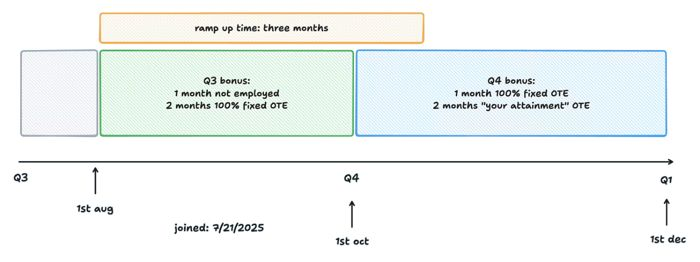

In [3]:
display(preview("img-p0617-x2727"))

## The prompt

The model gets the image plus where it sits (article, section, page) and ~1,500 characters before / ~800 after it.
It is asked for what the image adds beyond that text. This is the exact prompt for the communication tier list:

In [4]:
tier_list = next(r for r in records if r.image_id == "img-p0041-x258")
print(build_prompt(tier_list)[:900], "\n...\n", build_prompt(tier_list)[-1400:])

You are describing an image from the PostHog company handbook for a question-answering system.
The system only reads text, so your description is how this image's information reaches it.

Where the image appears:
- Article: Logos, brand, hedgehogs (contents/handbook/company/brand-assets.md)
- Section: Other fonts > Squeak > Examples
- Page: 41

Text just before the image:
<before>
 of Displaay's Matter SQ typeface (SQ stands for square dots):
1. Bold (titles and section headers)
2. Semibold (paragraphs accompanying headers and paragraph links)
3. Regular & Regular Italic (paragraph text)
Note that Regular and Regular Italic are lighter than the font-weight we use on the web, so paragraph text in Figma mockups will look noticeably thinner than how it appears on posthog.com.
When designing ads or other content with non-paragraph text, use Semibold instead of Regular.
We have a handful of l 
...
 ight mode.
We use the same set of colors, and only swap out a couple hues depending on the co

## Describing with the Claude API

Off by default; see the notes at the top. Requests run 8 at a time with structured output (a Pydantic schema),
effort `medium`, and server-side refusal fallback on the Claude API.

In [5]:
if RUN_API:
    done, errors = asyncio.run(describe_all(records, settings.llm, paths.image_descriptions, ROOT, force=FORCE))
    print("described", done, "| errors:", errors)
else:
    print("RUN_API is False: using cached descriptions")

RUN_API is False: using cached descriptions


## The descriptions

In [6]:
cache = load_cache(paths.image_descriptions)
current = {r.image_id: cache[r.image_id] for r in records if is_current(cache.get(r.image_id), r)}
print(f"{len(current)}/{len(records)} images have a current description (prompt {PROMPT_VERSION})")
print("by source:", dict(collections.Counter(e["source"] for e in current.values())))
print("by kind:", dict(collections.Counter(e["kind"] for e in current.values()).most_common()))
print("adds information beyond the text:", sum(e["adds_information"] for e in current.values()))
words = pd.Series([len(e["description"].split()) for e in current.values()])
print("description length in words: median", int(words.median()), "max", words.max())

77/77 images have a current description (prompt v1)
by source: {'claude-code-subagent': 77}
by kind: {'screenshot': 52, 'chart': 9, 'illustration': 4, 'diagram': 4, 'table': 3, 'logo': 2, 'meme': 1, 'photo': 1, 'other': 1}
adds information beyond the text: 52
description length in words: median 69 max 124


In [7]:
pd.DataFrame([{"image_id": i, "kind": e["kind"], "adds_info": e["adds_information"], "caption": e["caption"]}
              for i, e in current.items()])

,image_id,kind,adds_info,caption
0,img-p0003-x30,screenshot,True,Wireframe-style mockup of the posthog.com Changelog page showing a Feb 2023 entry for performance monitoring in sess...
1,img-p0037-x212,logo,False,"Cropped preview of the current PostHog logo, with the hedgehog logomark and the PostHog wordmark."
2,img-p0038-x244,logo,True,Comparison of the incorrect old PostHog logo with sharp corners against the correct current rounded logo.
3,img-p0040-x255,illustration,True,"Two hedgehog illustrations in the Squeak font style, labelled Average Book Fan and Average Docs Enjoyer."
4,img-p0041-x258,diagram,True,Communication tier list ranking PostHog communication methods from S tier to F tier.
...,...,...,...,...
72,img-p0871-x3936,other,True,"Legend from the Billing Deep Dive dashboard's breakdown by product and team_id, listing feature flag request and das..."
73,img-p0872-x3939,screenshot,True,Billing admin 'Add credit' form filled with amount 1500 and reason 'Unwanted Spike'.
74,img-p0873-x3942,screenshot,True,"Stripe customer page after issuing a credit note, showing two canceled payments and the 'Credit note from PostHog' e..."
75,img-p0951-x4297,illustration,False,"Cartoon illustration of hedgehogs with a browser dashboard, bar chart, laptop, map, chat bubbles and a send button, ..."


Three examples: the images whose content the text doesn't contain at all.

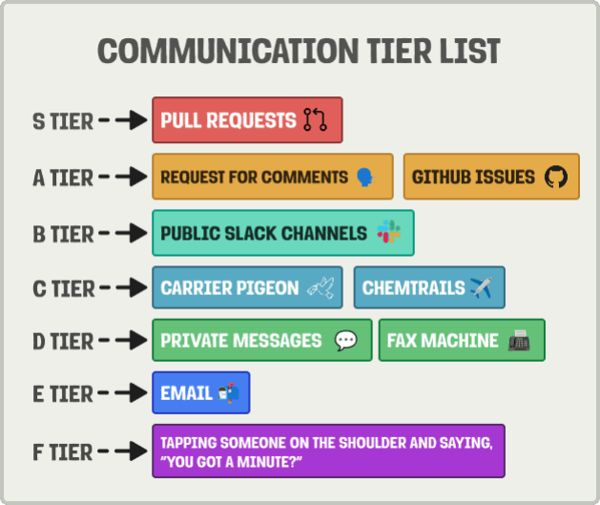

**img-p0041-x258**: Communication tier list ranking PostHog communication methods from S tier to F tier.

A tier list titled Communication tier list. S tier: Pull requests. A tier: Request for comments and GitHub issues. B tier: Public Slack channels. C tier: Carrier pigeon and Chemtrails. D tier: Private messages and Fax machine. E tier: Email. F tier: Tapping someone on the shoulder and saying, "You got a minute?". Each tier is a colored label with an icon. Some entries are jokes (carrier pigeon, chemtrails, fax machine). It ranks public, written, asynchronous channels highest and interruptive ones lowest.

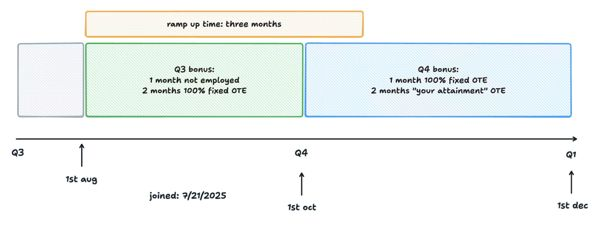

**img-p0617-x2727**: Timeline of a new hire's ramp period for someone who joined 7/21/2025, showing Q3 and Q4 bonus rules.

Hand-drawn timeline from Q3 through Q4 to Q1. Example hire joined 7/21/2025. A three-month ramp-up bar spans 1st Aug to about 1st Nov. Q3 bonus (from 1st Aug to 1st Oct): 1 month not employed, 2 months 100% fixed OTE. Q4 bonus (1st Oct to 1st Dec): 1 month 100% fixed OTE, 2 months 'your attainment' OTE. Markers: 1st Aug, 1st Oct (Q4), 1st Dec (Q1). A grey box before 1st Aug covers the pre-start part of Q3.

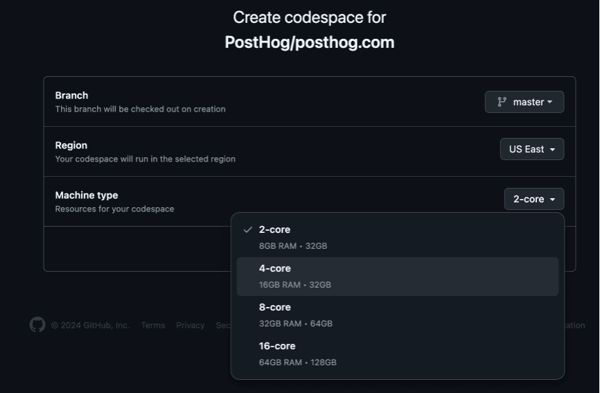

**img-p0355-x1727**: GitHub "Create codespace for PostHog/posthog.com" form with the Machine type dropdown open showing 2-core to 16-core options.

Form for PostHog/posthog.com with Branch master, Region US East, and Machine type currently 2-core. The open dropdown lists 2-core (8GB RAM, 32GB, currently checked), 4-core (16GB RAM, 32GB, highlighted), 8-core (32GB RAM, 64GB) and 16-core (64GB RAM, 128GB). The 4-core option is the one the steps say to choose.

In [8]:
for image_id in ["img-p0041-x258", "img-p0617-x2727", "img-p0355-x1727"]:
    entry = current[image_id]
    display(preview(image_id, 600))
    display(Markdown(f"**{image_id}**: {entry['caption']}\n\n{entry['description']}"))